## Модель

$$X_i=\mu+\sigma U_i,\qquad
U_i\sim0.9N(0,1)+0.1(5T_3).$$
Компоненты симметричны относительно нуля. Поэтому
$$F_U(u)=0.9\Phi(u)+0.1F_{T_3}(u/5),\qquad
f_U(u)=0.9\varphi(u)+\frac{0.1}{5}f_{T_3}(u/5).$$
Для моделирования фиксируем $\mu=2$, $\sigma=1.5$ и seed = 42. Seed нужен для воспроизводимости и выбран произвольно.

Параметр $\sigma$ задаёт масштаб модели. У $T_3$ дисперсия $3/(3-2)=3$, поэтому
$\operatorname{Var}(5T_3)=25\cdot3=75$. Поскольку средние обеих компонент равны нулю,
$$\operatorname{Var}(U)=0.9\cdot1+0.1\cdot75=8.4,\qquad
\operatorname{SD}(X)=\sigma\sqrt{8.4}.$$

In [1]:
from scipy.stats import norm, t
import numpy as np
from scipy.optimize import brentq, least_squares
from scipy.integrate import quad
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
epsilon = 0.1
outlier_scale = 5
df = 3
mu_true = 2
sigma_true = 1.5
seed = 42

In [3]:
def density(u):
    return (1 - epsilon) * norm.pdf(u) + epsilon * t.pdf(u / outlier_scale, df) / outlier_scale

def distribution(u):
    return (1 - epsilon) * norm.cdf(u) + epsilon * t.cdf(u / outlier_scale, df)

In [4]:
def make_sample(n, rng):
    u = rng.normal(size=n)
    is_outlier = rng.random(n) < epsilon
    u[is_outlier] = outlier_scale * rng.standard_t(df, size=is_outlier.sum())
    return mu_true + sigma_true * u

In [5]:
rng = np.random.default_rng(seed)
x = make_sample(400, rng)

print('Размер выборки:', len(x))
print('Первые 10 наблюдений:', np.round(x[:10], 3))

Размер выборки: 400
Первые 10 наблюдений: [ 2.457  0.44   3.126  3.411 -0.927  2.414  0.098  5.664  1.975  0.72 ]


## Оценка масштаба

Из предыдущего этапа используем модифицированную MADN:
$$\tilde x=\operatorname{Med}(x),\qquad
\mathrm{MAD}=\operatorname{Med}_i|x_i-\tilde x|,$$
$$\mathrm{MADN}=\frac{\mathrm{MAD}}{\Phi^{-1}(0.75)},\qquad
\boxed{\hat\sigma=\frac{\mathrm{MAD}}q},\quad F_U(q)=0.75.$$
Нормальная поправка $1/\Phi^{-1}(0.75)\approx1.4826$ не учитывает смесь.
Делитель $q$ обеспечивает состоятельность для нашей модели, поскольку
$P(|U|\le q)=1/2$, а медиана $|X-\mu|$ равна $\sigma q$.

In [6]:
q_normal = norm.ppf(0.75)
q = brentq(lambda u: distribution(u) - 0.75, 0, 20)

In [7]:
median_x = np.median(x)
mad = np.median(np.abs(x - median_x))
madn = mad / q_normal
sigma_madn = madn * q_normal / q

In [8]:
print(f'q для смеси: {q:.5f}')
print(f'Обычная MADN: {madn:.5f}')
print(f'Модифицированная MADN: {sigma_madn:.5f}')
print(f'Предельное завышение обычной MADN: {(q / q_normal - 1) * 100:.2f}%')

q для смеси: 0.74454
Обычная MADN: 1.52485
Модифицированная MADN: 1.38138
Предельное завышение обычной MADN: 10.39%


## Оценки положения методом M

Масштаб $\hat\sigma$ уже найден. При фиксированном масштабе положение определяем из уравнения
$$\boxed{\sum_{i=1}^n\psi_c\left(\frac{x_i-\hat\mu}{\hat\sigma}\right)=0}.$$
Рассматриваем две функции:
$$\psi_{H,c}(u)=\begin{cases}-c,&u<-c,\\u,&|u|\le c,\\c,&u>c,\end{cases}\qquad
\psi_{B,c}(u)=u(1-u^2/c^2)^2\mathbf1_{|u|<c}.$$
Для Губера используется поиск корня. Для bisquare используются итерации с началом в медиане:
$$u_i^{(k)}=\frac{x_i-\mu^{(k)}}{\hat\sigma},\quad
w_i^{(k)}=\max(1-(u_i^{(k)}/c)^2,0)^2,\quad
\mu^{(k+1)}=\frac{\sum_iw_i^{(k)}x_i}{\sum_iw_i^{(k)}}.$$

In [9]:
def huber(u, c):
    return np.clip(u, -c, c)

def bisquare(u, c):
    return u * np.maximum(1 - (u / c)**2, 0)**2

In [10]:
def find_mu(x, sigma, function, c):
    if function == 'Huber':
        return brentq(lambda mu: np.mean(huber((x - mu) / sigma, c)), x.min(), x.max())

    mu = np.median(x)
    for iteration in range(500):
        u = (x - mu) / sigma
        weights = np.maximum(1 - (u / c)**2, 0)**2
        if weights.sum() == 0:
            return np.nan
        mu_new = np.sum(weights * x) / weights.sum()

        if abs(mu_new - mu) < 1e-8 * sigma:
            u = (x - mu_new) / sigma
            derivative = np.where(np.abs(u) < c, (1 - (u / c)**2) * (1 - 5 * (u / c)**2), 0)
            if derivative.mean() <= 0 or abs(bisquare(u, c).mean()) > 1e-7:
                return np.nan
            return mu_new
        mu = mu_new

    return np.nan

In [11]:
location_options = [('Huber', 1.345), ('Huber', 2),
                    ('Bisquare', 3), ('Bisquare', 4.685)]

In [12]:
sample_rows = []
for function, c in location_options:
    mu_hat = find_mu(x, sigma_madn, function, c)
    sample_rows.append([function, c, mu_hat, sigma_madn])

In [13]:
sample_table = pd.DataFrame(sample_rows, columns=['function', 'c', 'mu_hat', 'sigma_MADN'])
display(sample_table.round(5))

,function,c,mu_hat,sigma_MADN
0,Huber,1.345,1.89638,1.38138
1,Huber,2.000,1.88957,1.38138
2,Bisquare,3.000,1.93463,1.38138
3,Bisquare,4.685,1.91220,1.38138


### Асимптотические дисперсии и выбор оценки

Параметр $c$ влияет на точность. Для сравнения настроек используем
$$\sqrt n(\hat\mu-\mu)\xrightarrow{d}N(0,\sigma^2V_\mu),\qquad
\boxed{V_\mu(c)=\frac{E\psi_c(U)^2}{(E\psi'_c(U))^2}}.$$
Таким образом, $\operatorname{Var}(\hat\mu)\approx\sigma^2V_\mu/n$.
При симметрии $E[U\psi'(U)]=0$, поэтому подстановка состоятельной MADN не меняет дисперсию первого порядка.

Обозначим $a(c)=E\psi'_c(U)$ и $b_\mu(c)=E\psi_c(U)^2$.
Для Губера:
$$a_H(c)=2F_U(c)-1,\qquad
b_{\mu,H}(c)=2\int_0^c u^2f_U(u)\,du+2c^2[1-F_U(c)].$$
Для bisquare:
$$a_B(c)=2\int_0^c(1-u^2/c^2)(1-5u^2/c^2)f_U(u)\,du,$$
$$b_{\mu,B}(c)=2\int_0^c u^2(1-u^2/c^2)^4f_U(u)\,du.$$

In [15]:
location_rows = []

for c in np.linspace(0.3, 3.5, 65):
    a = 2 * distribution(c) - 1
    b = 2 * quad(lambda u: u**2 * density(u), 0, c)[0]
    b = b + 2 * c**2 * (1 - distribution(c))
    location_rows.append(['Huber', c, b / a**2])

In [16]:
for c in np.linspace(1.5, 8, 66):
    a = 2 * quad(lambda u: (1 - (u / c)**2) * (1 - 5 * (u / c)**2) * density(u), 0, c)[0]
    b = 2 * quad(lambda u: bisquare(u, c)**2 * density(u), 0, c)[0]
    location_rows.append(['Bisquare', c, b / a**2])

In [17]:
location_table = pd.DataFrame(location_rows, columns=['function', 'c', 'V_mu'])
huber_table = location_table[location_table['function'] == 'Huber']
bisquare_table = location_table[location_table['function'] == 'Bisquare']

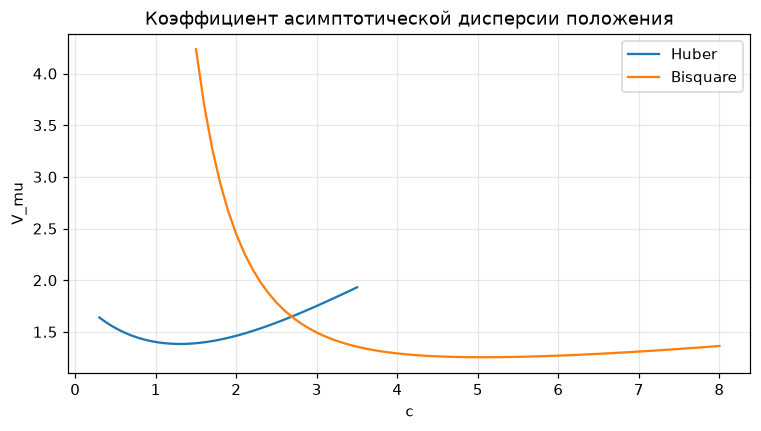

In [18]:
plt.figure(figsize=(8, 4))
plt.plot(huber_table['c'], huber_table['V_mu'], label='Huber')
plt.plot(bisquare_table['c'], bisquare_table['V_mu'], label='Bisquare')
plt.xlabel('c')
plt.ylabel('V_mu')
plt.title('Коэффициент асимптотической дисперсии положения')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [19]:
best_huber = huber_table.loc[huber_table['V_mu'].idxmin()]
best_bisquare = bisquare_table.loc[bisquare_table['V_mu'].idxmin()]
c_huber = best_huber['c']
c_bisquare = best_bisquare['c']

display(pd.DataFrame([best_huber, best_bisquare]).round(5))

,function,c,V_mu
20,Huber,1.3,1.38323
101,Bisquare,5.1,1.25456


Минимумы на сетке: для Губера $c=1.3$, $V_\mu\approx1.3832$; для bisquare $c=5.1$,
$V_\mu\approx1.2546$. Для этой смеси выбираем bisquare при $c=5.1$.
Оценки с найденными настройками добавляем к исходным вариантам для дальнейшей эмпирической проверки.

In [20]:
location_options += [('Huber', c_huber), ('Bisquare', c_bisquare)]

best_sample_rows = []
for function, c in [('Huber', c_huber), ('Bisquare', c_bisquare)]:
    mu_hat = find_mu(x, sigma_madn, function, c)
    best_sample_rows.append([function, c, mu_hat])
display(pd.DataFrame(best_sample_rows, columns=['function', 'c', 'mu_hat']).round(5))

,function,c,mu_hat
0,Huber,1.3,1.89646
1,Bisquare,5.1,1.90683


## Совместное оценивание положения и масштаба

Теперь $\mu$ и $\sigma$ неизвестны одновременно. Решаем систему
$$\boxed{\begin{cases}
\displaystyle\frac1n\sum_i\psi_c\left(\frac{x_i-\hat\mu}{\hat\sigma}\right)=0,\\[6pt]
\displaystyle\frac1n\sum_i\chi_d\left(\frac{x_i-\hat\mu}{\hat\sigma}\right)=b_d,
\end{cases}}\qquad b_d=E_F\chi_d(U).$$
Первое уравнение определяет положение, второе определяет масштаб. Здесь $\chi=\rho_{\mathrm{scale}}$.
Рассматриваем bisquare и ограниченную квадратичную функцию:
$$\chi_{B,d}(u)=1-\max(1-u^2/d^2,0)^3,\qquad
\chi_{H,d}(u)=\min(u^2/d^2,1).$$
Для масштаба bisquare берём $d=2,3$; для ограниченной квадратичной функции берём $d=1.5,2$.
Калибровка под смесь нужна, чтобы уравнение масштаба выполнялось при истинных параметрах:
$$b_d=2\int_0^d\chi_d(u)f_U(u)\,du+2[1-F_U(d)].$$
Последнее слагаемое учитывает хвосты, где $\chi_d=1$.

In [21]:
def scale_bisquare(u, d):
    return 1 - np.maximum(1 - (u / d)**2, 0)**3

def scale_huber(u, d):
    return np.minimum((u / d)**2, 1)

In [22]:
scale_options = [('Bisquare', 2), ('Bisquare', 3),
                 ('Clipped quadratic', 1.5), ('Clipped quadratic', 2)]

In [23]:
scale_rows = []
for function, d in scale_options:
    if function == 'Bisquare':
        rho = scale_bisquare
    else:
        rho = scale_huber

    tail_probability = 2 * (1 - distribution(d))
    b = 2 * quad(lambda u: rho(u, d) * density(u), 0, d)[0] + tail_probability
    scale_rows.append([function, d, b])

In [24]:
scale_table = pd.DataFrame(scale_rows, columns=['function', 'd', 'b'])
display(scale_table.round(5))

,function,d,b
0,Bisquare,2.0,0.44452
1,Bisquare,3.0,0.29874
2,Clipped quadratic,1.5,0.39686
3,Clipped quadratic,2.0,0.28792


В качестве начальных значений для системы используем медиану и модифицированную MADN.
Для удобства расчёта используем $y_i=(x_i-\tilde x)/s_0$, где $s_0=\hat\sigma_{\mathrm{MADN}}$,
и параметризуем положительный масштаб как $s=e^\eta$.
После решения возвращаем исходные единицы:
$$\hat\mu=\tilde x+s_0\hat m,\qquad \hat\sigma=s_0e^{\hat\eta}.$$

In [25]:
def joint_equations(parameters, y, location_function, c, scale_function, d, b):
    mu, log_sigma = parameters
    u = (y - mu) / np.exp(log_sigma)

    if location_function == 'Huber':
        equation_mu = huber(u, c).mean()
    else:
        equation_mu = bisquare(u, c).mean()

    if scale_function == 'Bisquare':
        equation_sigma = scale_bisquare(u, d).mean() - b
    else:
        equation_sigma = scale_huber(u, d).mean() - b
    return [equation_mu, equation_sigma]

In [26]:
def find_joint(x, location_function, c, scale_function, d, b):
    median = np.median(x)
    sigma_start = np.median(np.abs(x - median)) / q
    if sigma_start <= 0:
        return np.nan, np.nan
    y = (x - median) / sigma_start

    result = least_squares(joint_equations, [0, 0],
                           args=(y, location_function, c, scale_function, d, b), bounds=([-np.inf, -8], [np.inf, 8]),
                           xtol=1e-9, ftol=1e-9, gtol=1e-9, max_nfev=300)
    if not result.success or np.max(np.abs(joint_equations(result.x, y, location_function, c, scale_function, d, b))) > 1e-7:
        return np.nan, np.nan

    mu, log_sigma = result.x
    u = (y - mu) / np.exp(log_sigma)
    if location_function == 'Bisquare':
        derivative = np.where(np.abs(u) < c, (1 - (u / c)**2) * (1 - 5 * (u / c)**2), 0)
        if derivative.mean() <= 0:
            return np.nan, np.nan

    mu_hat = median + sigma_start * mu
    sigma_hat = sigma_start * np.exp(log_sigma)
    return mu_hat, sigma_hat

In [27]:
joint_options = []
for location_function, c in [('Huber', c_huber), ('Bisquare', c_bisquare)]:
    for row in scale_table.itertuples(index=False):
        joint_options.append((location_function, c, row.function, row.d, row.b))

In [28]:
joint_rows = []
for location_function, c, scale_function, d, b in joint_options:
    mu_hat, sigma_hat = find_joint(x, location_function, c, scale_function, d, b)
    joint_rows.append([location_function, c, scale_function, d, mu_hat, sigma_hat])

In [29]:
joint_table = pd.DataFrame(joint_rows, columns=['psi', 'c', 'rho', 'd', 'mu_hat', 'sigma_hat'])
display(joint_table.round(5))

,psi,c,rho,d,mu_hat,sigma_hat
0,Huber,1.3,Bisquare,2.0,1.89635,1.39602
1,Huber,1.3,Bisquare,3.0,1.89635,1.40109
2,Huber,1.3,Clipped quadratic,1.5,1.89635,1.39528
3,Huber,1.3,Clipped quadratic,2.0,1.89635,1.40060
4,Bisquare,5.1,Bisquare,2.0,1.90619,1.39557
5,Bisquare,5.1,Bisquare,3.0,1.90595,1.40087
6,Bisquare,5.1,Clipped quadratic,1.5,1.90621,1.39514
7,Bisquare,5.1,Clipped quadratic,2.0,1.90598,1.40023


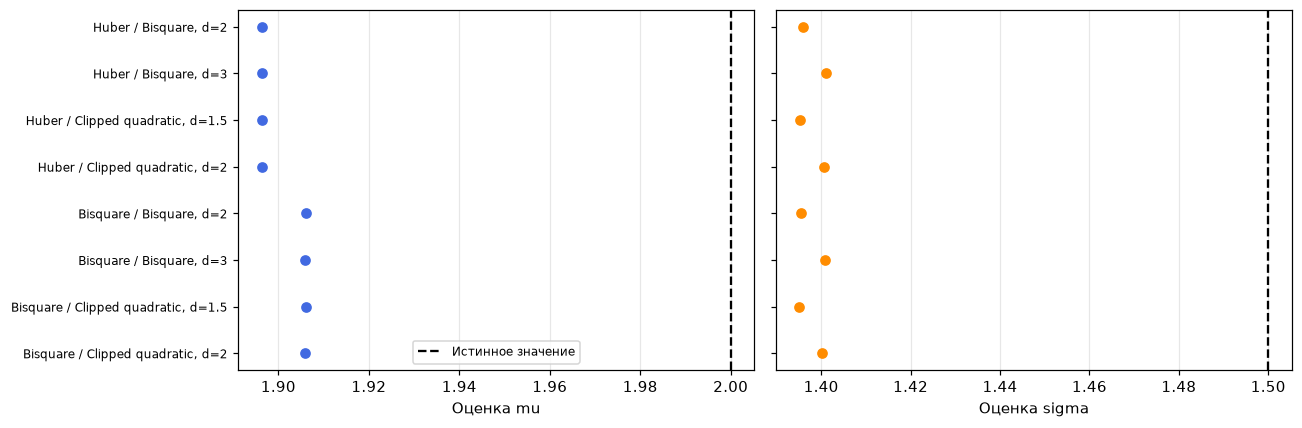

In [31]:
joint_labels = []
for row in joint_table.itertuples(index=False):
    joint_labels.append(f'{row.psi} / {row.rho}, d={row.d:g}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
positions = np.arange(len(joint_table))
axes[0].plot(joint_table['mu_hat'], positions, 'o', color='royalblue')
axes[1].plot(joint_table['sigma_hat'], positions, 'o', color='darkorange')
axes[0].axvline(mu_true, color='black', linestyle='--', label='Истинное значение')
axes[1].axvline(sigma_true, color='black', linestyle='--')
axes[0].set_xlabel('Оценка mu')
axes[1].set_xlabel('Оценка sigma')

axes[0].set_yticks(positions, joint_labels, fontsize=8)
axes[1].set_yticks(positions, [])
for ax in axes:
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Эмпирическая проверка

В моделировании истинные параметры известны: $\mu=2$, $\sigma=1.5$.
Используем по 400 выборок объёма $n=100,400,1000$; в каждом повторении масштаб и положение оцениваются заново.
Все методы получают одни и те же данные.

Для успешных повторений $r=1,\ldots,R_*$ и параметра $p=\mu$ или $\sigma$:
$$\operatorname{Bias}(\hat p)=\overline{\hat p}-p,\qquad
\operatorname{RMSE}(\hat p)=\sqrt{\frac1{R_*}\sum_{r=1}^{R_*}(\hat p^{(r)}-p)^2}.$$
Теоретическую дисперсию положения сопоставляем с коэффициентом
$$V_{\mu,\mathrm{emp}}=\frac{n}{\sigma_{\mathrm{true}}^2}
\frac1{R_*-1}\sum_{r=1}^{R_*}(\hat\mu^{(r)}-\overline{\hat\mu})^2.$$
Ожидаем уменьшения ошибок при росте $n$ и согласования эмпирического коэффициента с $V_\mu$.
Число неудачных решений сохраняется в столбце `failures`; такие решения исключены из расчёта ошибок.

In [32]:
repeats = 400
sample_sizes = [100, 400, 1000]
rng = np.random.default_rng(seed + 1)

In [33]:
names = []
for function, c in location_options:
    names.append(f'{function} c={c:g} + MADN')
for location_function, c, scale_function, d, b in joint_options:
    names.append(f'{location_function} + {scale_function} d={d:g}')

In [34]:
samples_by_n = {}
estimates_by_n = {}

for n in sample_sizes:
    samples_by_n[n] = [make_sample(n, rng) for repetition in range(repeats)]
    estimates_by_n[n] = np.full((repeats, len(names), 2), np.nan)

In [35]:
for n in sample_sizes:
    for repetition, sample in enumerate(samples_by_n[n]):
        sigma_hat = np.median(np.abs(sample - np.median(sample))) / q

        for j, (function, c) in enumerate(location_options):
            try:
                mu_hat = find_mu(sample, sigma_hat, function, c)
                estimates_by_n[n][repetition, j] = [mu_hat, sigma_hat]
            except (RuntimeError, ValueError):
                pass

In [36]:
for n in sample_sizes:
    for repetition, sample in enumerate(samples_by_n[n]):
        for j, (location_function, c, scale_function, d, b) in enumerate(joint_options, start=len(location_options)):
            try:
                estimates_by_n[n][repetition, j] = find_joint(sample, location_function, c, scale_function, d, b)
            except (RuntimeError, ValueError):
                pass
    print(f'Готово: n={n}, повторений={repeats}')

Готово: n=100, повторений=400
Готово: n=400, повторений=400
Готово: n=1000, повторений=400


In [37]:
simulation_rows = []
for n in sample_sizes:
    estimates = estimates_by_n[n]
    for j, name in enumerate(names):
        good = np.isfinite(estimates[:, j]).all(axis=1)
        failures = repeats - good.sum()
        if good.sum() < 2:
            simulation_rows.append([n, name, np.nan, np.nan, np.nan, np.nan, np.nan, failures])
            continue
        mu_values = estimates[good, j, 0]
        sigma_values = estimates[good, j, 1]

        bias_mu = mu_values.mean() - mu_true
        bias_sigma = sigma_values.mean() - sigma_true
        rmse_mu = np.sqrt(np.mean((mu_values - mu_true)**2))
        rmse_sigma = np.sqrt(np.mean((sigma_values - sigma_true)**2))
        v_mu = n * mu_values.var(ddof=1) / sigma_true**2
        simulation_rows.append([n, name, bias_mu, bias_sigma, rmse_mu, rmse_sigma, v_mu, failures])

In [38]:
simulation = pd.DataFrame(simulation_rows, columns=['n', 'method', 'bias_mu', 'bias_sigma',
                                                  'RMSE_mu', 'RMSE_sigma', 'V_mu_emp', 'failures'])
display(simulation.round(5))

,n,method,bias_mu,bias_sigma,RMSE_mu,RMSE_sigma,V_mu_emp,failures
0,100,Huber c=1.345 + MADN,-0.00543,-0.01974,0.18108,0.18349,1.45969,0
1,100,Huber c=2 + MADN,-0.00436,-0.01974,0.18706,0.18349,1.55826,0
2,100,Bisquare c=3 + MADN,-0.01088,-0.01974,0.18970,0.18349,1.59804,0
3,100,Bisquare c=4.685 + MADN,-0.00830,-0.01974,0.17553,0.18349,1.36974,0
4,100,Huber c=1.3 + MADN,-0.00555,-0.01974,0.18104,0.18349,1.45896,0
5,100,Bisquare c=5.1 + MADN,-0.00804,-0.01974,0.17554,0.18349,1.37002,0
6,100,Huber + Bisquare d=2,-0.00552,-0.01152,0.18044,0.14557,1.44930,0
7,100,Huber + Bisquare d=3,-0.00561,-0.01049,0.18038,0.14671,1.44835,0
8,100,Huber + Clipped quadratic d=1.5,-0.00552,-0.01359,0.18034,0.14430,1.44768,0
9,100,Huber + Clipped quadratic d=2,-0.00567,-0.01146,0.18039,0.14646,1.44843,0


In [39]:
comparison_rows = []
for function, c, v_mu in [('Huber', c_huber, best_huber['V_mu']),
                          ('Bisquare', c_bisquare, best_bisquare['V_mu'])]:
    name = f'{function} c={c:g} + MADN'
    row = simulation[(simulation['n'] == max(sample_sizes)) & (simulation['method'] == name)].iloc[0]
    comparison_rows.append([name, v_mu, row['V_mu_emp']])

In [40]:
comparison = pd.DataFrame(comparison_rows, columns=['method', 'V_mu_theory', 'V_mu_emp'])
display(comparison.round(5))

,method,V_mu_theory,V_mu_emp
0,Huber c=1.3 + MADN,1.38323,1.38054
1,Bisquare c=5.1 + MADN,1.25456,1.24837


In [42]:
selected_names = [f'Huber c={c_huber:g} + MADN', f'Bisquare c={c_bisquare:g} + MADN',
                  'Huber + Clipped quadratic d=2', 'Bisquare + Clipped quadratic d=2']

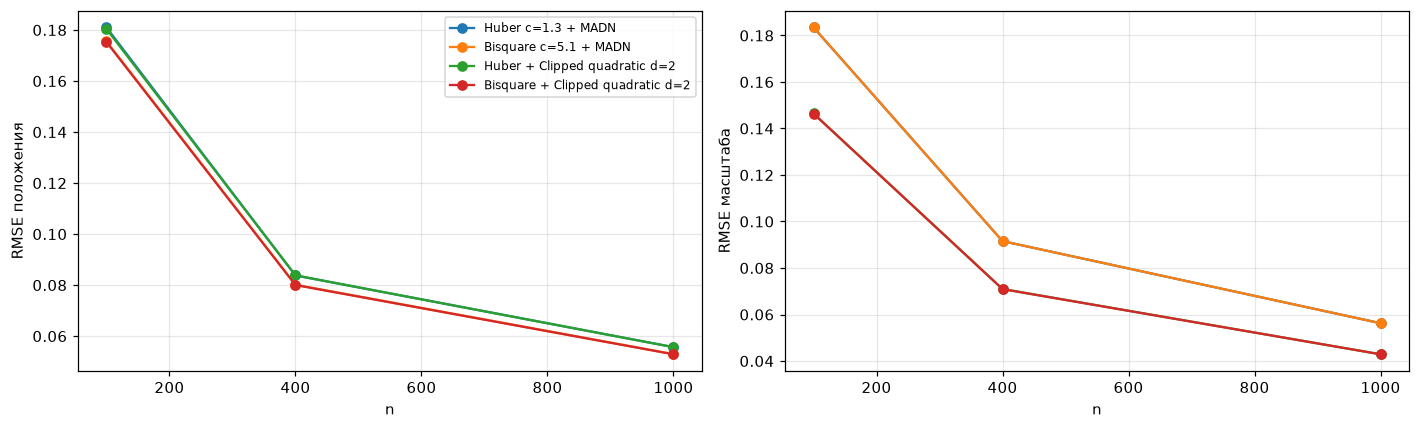

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in selected_names:
    rows = simulation[simulation['method'] == name]
    axes[0].plot(rows['n'], rows['RMSE_mu'], 'o-', label=name)
    axes[1].plot(rows['n'], rows['RMSE_sigma'], 'o-', label=name)

axes[0].set_ylabel('RMSE положения')
axes[1].set_ylabel('RMSE масштаба')
axes[0].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel('n')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Выводы

Оценки положения получены для разных настроек Губера и bisquare. Численное сравнение дисперсий
для заданной смеси показывает преимущество bisquare при $c=5.1$:
$V_\mu=1.2546$ против $1.3832$ у лучшей настройки Губера.
При $n=1000$ эмпирический коэффициент равен 1.2484.

RMSE выбранной оценки положения уменьшилась с 0.1755 при $n=100$
до 0.0529 при $n=1000$.
У совместной оценки bisquare с ограниченной квадратичной функцией масштаба ($d=2$)
при $n=1000$ RMSE положения равна 0.0529, RMSE масштаба равна 0.0429.